In [ ]:
# Imports and load dataset
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)

# If using Google Colab, upload the CSV when prompted.
from google.colab import files
uploaded = files.upload()

# Automatically read the uploaded CSV.
csv_name = next(name for name in uploaded.keys() if name.lower().endswith(".csv"))
df = pd.read_csv(csv_name)

print("Dataset shape:", df.shape)
display(df.head())

Saving neo_asteroid_dataset.csv to neo_asteroid_dataset.csv
Dataset shape: (42815, 21)


,spkid,pdes,full_name,kind,neo,pha,e,a,q,i,...,w,moid,H,diameter,albedo,first_obs,last_obs,data_arc,n_obs_used,condition_code
0,20000433,433,433 Eros (A898 PA),an,Y,N,0.2229,1.458,1.133,10.83,...,178.92,0.1490,10.40,16.840,0.250,1893-10-29,2021-05-13,46582.0,9130,0.0
1,20000719,719,719 Albert (A911 TB),an,Y,N,0.5466,2.637,1.196,11.57,...,156.18,0.2020,15.59,NaN,NaN,1911-10-04,2026-05-22,41869.0,2147,0.0
2,20000887,887,887 Alinda (A918 AA),an,Y,N,0.5711,2.474,1.061,9.40,...,350.55,0.0801,13.82,4.200,0.310,1918-02-09,2025-08-27,39281.0,5843,0.0
3,20001036,1036,1036 Ganymed (A924 UB),an,Y,N,0.5335,2.664,1.243,26.69,...,132.51,0.3420,9.17,37.675,0.238,1924-10-23,2026-06-30,37140.0,13637,0.0
4,20001221,1221,1221 Amor (1932 EA1),an,Y,N,0.4347,1.920,1.085,11.87,...,26.75,0.1090,17.37,1.000,NaN,1932-03-12,2026-10-20,34555.0,737,0.0


In [ ]:
# Dataset audit
print("Original rows:", len(df))
print("\\nPHA values including missing:")
print(df["pha"].value_counts(dropna=False))

df = df[df["pha"].isin(["Y", "N"])].copy()

print("\\nLabelled rows:", len(df))
print("\\nPHA class counts:")
print(df["pha"].value_counts())
print("\\nPHA class percentages:")
print((df["pha"].value_counts(normalize=True) * 100).round(2))
print("\\nDiameter missing:", df["diameter"].isna().sum())
print("Diameter missing percentage:", round(df["diameter"].isna().mean() * 100, 2), "%")

Original rows: 42815
\nPHA values including missing:
pha
N      40130
Y       2550
NaN      135
Name: count, dtype: int64
\nLabelled rows: 42680
\nPHA class counts:
pha
N    40130
Y     2550
Name: count, dtype: int64
\nPHA class percentages:
pha
N    94.03
Y     5.97
Name: proportion, dtype: float64
\nDiameter missing: 41434
Diameter missing percentage: 97.08 %


In [ ]:
# Feature selection and leakage precautions
# Selected features:
# - a: semi-major axis
# - e: eccentricity
# - i: inclination
# - om: longitude of ascending node
# - w: argument of perihelion
# - diameter: effective diameter
FEATURES = ["a", "e", "i", "om", "w", "diameter"]
TARGET = "pha"

X = df[FEATURES].copy()
y = df[TARGET].map({"N": 0, "Y": 1}).astype(int)

print("Features:", FEATURES)
print("X shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

Features: ['a', 'e', 'i', 'om', 'w', 'diameter']
X shape: (42680, 6)
Target distribution:
pha
0    40130
1     2550
Name: count, dtype: int64


In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\\nPHA rate in training set:", round(y_train.mean() * 100, 2), "%")
print("PHA rate in test set:", round(y_test.mean() * 100, 2), "%")

Training rows: 34144
Testing rows: 8536
\nPHA rate in training set: 5.97 %
PHA rate in test set: 5.97 %


In [ ]:
# Random Forest baseline
rf_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("random_forest", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
# Evaluation
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}

results_df = pd.DataFrame(
    {"Metric": list(results.keys()), "Score": list(results.values())}
)
display(results_df.round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Non-PHA", "PHA"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.9419
1,Precision,0.8500
2,Recall,0.0333
3,F1-score,0.0642
4,ROC-AUC,0.7983
5,Average Precision,0.2658


Confusion Matrix:
[[8023    3]
 [ 493   17]]
\nClassification Report:
              precision    recall  f1-score   support

     Non-PHA       0.94      1.00      0.97      8026
         PHA       0.85      0.03      0.06       510

    accuracy                           0.94      8536
   macro avg       0.90      0.52      0.52      8536
weighted avg       0.94      0.94      0.92      8536



In [ ]:
# Save predictions and results
predictions = pd.DataFrame({
    "row_index": X_test.index,
    "y_true": y_test.values,
    "y_pred": y_pred,
    "y_probability": y_prob
})
predictions.to_csv("random_forest_baseline_predictions.csv", index=False)
results_df.to_csv("random_forest_baseline_metrics.csv", index=False)

print("Saved:")
print("- random_forest_baseline_predictions.csv")
print("- random_forest_baseline_metrics.csv")

files.download("random_forest_baseline_predictions.csv")
files.download("random_forest_baseline_metrics.csv")

Saved:
- random_forest_baseline_predictions.csv
- random_forest_baseline_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload neo_asteroid_dataset.csv


Saving neo_asteroid_dataset.csv to neo_asteroid_dataset (1).csv

Dataset loaded successfully!
Original shape: (42815, 21)

Cleaned dataset shape: (42680, 6)
PHA records: 2550
Non-PHA records: 40130

Training records: 34144
Testing records: 8536

Model training records: 27315
Validation records: 6829

========== VALIDATION THRESHOLD SELECTION ==========
Minimum precision requirement: 0.2
Selected threshold: 0.1467
Validation precision: 0.2005
Validation recall: 0.3701

========== FINAL TEST RESULTS ==========
                         Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  Average Precision
Random Forest - Threshold 0.50    0.9414     0.7500  0.0294    0.0566   0.7963             0.2599
  Random Forest - Recall Tuned    0.8852     0.2412  0.4294    0.3089   0.7963             0.2599

Confusion Matrix - Default Threshold
[[8021    5]
 [ 495   15]]

Confusion Matrix - Recall-Tuned Threshold
[[7337  689]
 [ 291  219]]

Classification Report - Recall-Tuned Model
             

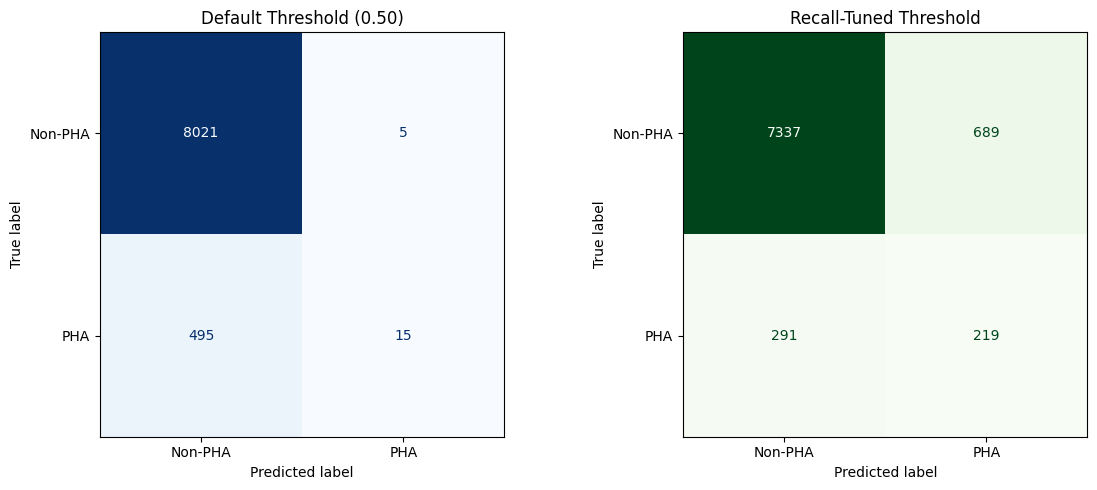

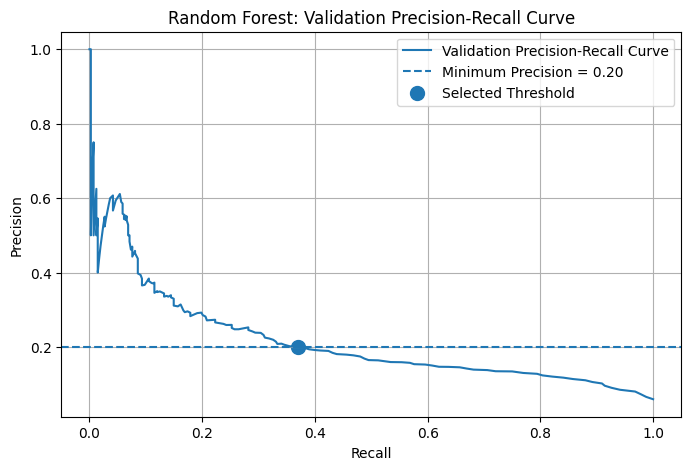


All output files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========== RESEARCH INTERPRETATION ==========
Selected threshold: 0.1467
Default threshold recall: 2.94 %
Recall-tuned threshold recall: 42.94 %
Default threshold precision: 75.0 %
Recall-tuned threshold precision: 24.12 %

The threshold was selected using validation data only. The test set was kept separate for final evaluation.


In [ ]:

# ============================================================
# RANDOM FOREST: RECALL-FOCUSED THRESHOLD TUNING
# Research: ML-Based Classification of Potentially Hazardous NEOs
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. UPLOAD AND LOAD DATASET
# ------------------------------------------------------------

print("Upload neo_asteroid_dataset.csv")
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("\nDataset loaded successfully!")
print("Original shape:", df.shape)

# ------------------------------------------------------------
# 2. DATA PREPROCESSING
# ------------------------------------------------------------

# Remove rows where target label is missing
df = df.dropna(subset=["pha"]).copy()

# Convert target labels into numeric values
df["pha"] = df["pha"].astype(str).str.strip().str.upper()
df = df[df["pha"].isin(["Y", "N"])].copy()

df["pha"] = df["pha"].map({"N": 0, "Y": 1})

# Selected research features
features = ["a", "e", "i", "om", "w", "diameter"]

X = df[features].copy()
y = df["pha"].copy()

# Convert features to numeric values
for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("\nCleaned dataset shape:", X.shape)
print("PHA records:", int(y.sum()))
print("Non-PHA records:", int((y == 0).sum()))

# ------------------------------------------------------------
# 3. CREATE THE SAME 80:20 TEST SPLIT
# ------------------------------------------------------------

# This recreates the original stratified test split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# ------------------------------------------------------------
# 4. SPLIT TRAINING DATA INTO TRAIN AND VALIDATION
# ------------------------------------------------------------

# Test data is not used for threshold selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\nModel training records:", len(X_fit))
print("Validation records:", len(X_val))

# ------------------------------------------------------------
# 5. BUILD RANDOM FOREST MODEL
# ------------------------------------------------------------

rf_model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train only on the training portion
rf_model.fit(X_fit, y_fit)

# ------------------------------------------------------------
# 6. SELECT THRESHOLD USING VALIDATION DATA
# ------------------------------------------------------------

val_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# Minimum acceptable precision
MIN_PRECISION = 0.20

# The final precision and recall entries do not have
# corresponding threshold values, so exclude them.
valid_mask = precision_values[:-1] >= MIN_PRECISION

if not np.any(valid_mask):
    raise ValueError(
        "No threshold satisfies the minimum precision target. "
        "Try lowering MIN_PRECISION."
    )

valid_indices = np.where(valid_mask)[0]

# Choose the threshold with the highest recall.
# If multiple thresholds have the same recall,
# choose the one with the highest precision.
best_index = max(
    valid_indices,
    key=lambda i: (recall_values[i], precision_values[i])
)

best_threshold = thresholds[best_index]

print("\n========== VALIDATION THRESHOLD SELECTION ==========")
print("Minimum precision requirement:", MIN_PRECISION)
print("Selected threshold:", round(best_threshold, 4))
print("Validation precision:", round(precision_values[best_index], 4))
print("Validation recall:", round(recall_values[best_index], 4))

# ------------------------------------------------------------
# 7. EVALUATE ON UNTOUCHED TEST DATA
# ------------------------------------------------------------

test_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Default threshold predictions
default_predictions = (test_probabilities >= 0.50).astype(int)

# Recall-focused threshold predictions
tuned_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# ------------------------------------------------------------
# 8. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

def calculate_metrics(y_true, predictions, probabilities, name):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(
            y_true, probabilities
        )
    }

default_metrics = calculate_metrics(
    y_test,
    default_predictions,
    test_probabilities,
    "Random Forest - Threshold 0.50"
)

tuned_metrics = calculate_metrics(
    y_test,
    tuned_predictions,
    test_probabilities,
    "Random Forest - Recall Tuned"
)

results = pd.DataFrame([
    default_metrics,
    tuned_metrics
])

print("\n========== FINAL TEST RESULTS ==========")
print(results.round(4).to_string(index=False))

# ------------------------------------------------------------
# 9. CONFUSION MATRICES
# ------------------------------------------------------------

cm_default = confusion_matrix(
    y_test,
    default_predictions,
    labels=[0, 1]
)

cm_tuned = confusion_matrix(
    y_test,
    tuned_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix - Default Threshold")
print(cm_default)

print("\nConfusion Matrix - Recall-Tuned Threshold")
print(cm_tuned)

print("\nClassification Report - Recall-Tuned Model")
print(classification_report(
    y_test,
    tuned_predictions,
    target_names=["Non-PHA", "PHA"],
    zero_division=0
))

# ------------------------------------------------------------
# 10. VISUALIZE CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_default,
    display_labels=["Non-PHA", "PHA"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Default Threshold (0.50)")

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Non-PHA", "PHA"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Recall-Tuned Threshold")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PRECISION-RECALL CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values,
    precision_values,
    label="Validation Precision-Recall Curve"
)

plt.axhline(
    y=MIN_PRECISION,
    linestyle="--",
    label="Minimum Precision = 0.20"
)

plt.scatter(
    recall_values[best_index],
    precision_values[best_index],
    marker="o",
    s=100,
    label="Selected Threshold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest: Validation Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

# Save metrics
results.to_csv(
    "random_forest_threshold_tuning_metrics.csv",
    index=False
)

# Save predictions with original dataset row indices
predictions_df = pd.DataFrame({
    "original_row_index": X_test.index,
    "actual_pha": y_test.values,
    "predicted_probability": test_probabilities,
    "default_prediction": default_predictions,
    "tuned_prediction": tuned_predictions
})

predictions_df.to_csv(
    "random_forest_threshold_tuning_predictions.csv",
    index=False
)

# Save selected threshold separately
threshold_info = pd.DataFrame([{
    "minimum_validation_precision": MIN_PRECISION,
    "selected_threshold": best_threshold,
    "validation_precision": precision_values[best_index],
    "validation_recall": recall_values[best_index]
}])

threshold_info.to_csv(
    "random_forest_selected_threshold.csv",
    index=False
)

print("\nAll output files saved successfully!")

files.download("random_forest_threshold_tuning_metrics.csv")
files.download("random_forest_threshold_tuning_predictions.csv")
files.download("random_forest_selected_threshold.csv")

# ------------------------------------------------------------
# 13. FINAL INTERPRETATION
# ------------------------------------------------------------

print("\n========== RESEARCH INTERPRETATION ==========")

print("Selected threshold:", round(best_threshold, 4))

print(
    "Default threshold recall:",
    round(default_metrics["Recall"] * 100, 2), "%"
)

print(
    "Recall-tuned threshold recall:",
    round(tuned_metrics["Recall"] * 100, 2), "%"
)

print(
    "Default threshold precision:",
    round(default_metrics["Precision"] * 100, 2), "%"
)

print(
    "Recall-tuned threshold precision:",
    round(tuned_metrics["Precision"] * 100, 2), "%"
)

print(
    "\nThe threshold was selected using validation data only. "
    "The test set was kept separate for final evaluation."
)
